In [1]:
%pip install numpy  # install the libraries into this notebook's Python

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: Invalid requirement: '#': Expected package name at the start of dependency specifier
    #
    ^


In [2]:
%pip install pandas 

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import numpy as np #NumPy for the math
import pandas as pd #Pandas to read and organize the data
import matplotlib.pyplot as plt #Matplotlib to draw the graph

In [5]:
inflation = pd.read_csv('STATIC_INFLATIONCALC.csv', skiprows=8)
display(inflation)

,date,STATIC_INFLATIONCALC
0,1914-01-01,6.0
1,1914-02-01,6.0
2,1914-03-01,6.0
3,1914-04-01,6.0
4,1914-05-01,5.9
...,...,...
1350,2026-05-01,169.6
1351,2026-06-01,169.0
1352,2026-07-01,169.9
1353,2026-08-01,169.8


In [6]:
inflation.columns = ['date', 'CPI'] #rename columns
inflation['date'] = pd.to_datetime(inflation['date']) #change the dates from text to dates
inflation['change'] = inflation['CPI'].pct_change(12) * 100 #pandas function which shows annual % change per 12 month period: each month vs same month last year

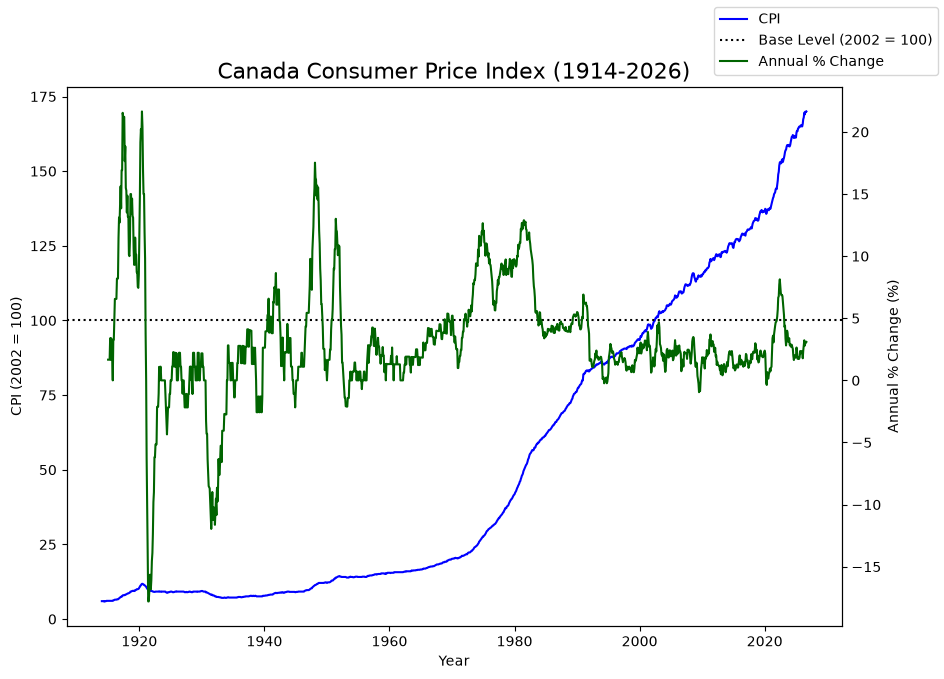

In [7]:
fig, ax = plt.subplots(figsize=(10,7))

ax.plot(inflation['date'], inflation['CPI'], color='blue', label='CPI') #CPI line
ax.axhline(100, color='black', linestyle=':', label='Base Level (2002 = 100)') #dotted line at base level
ax.set_xlabel('Year')
ax.set_ylabel('CPI (2002 = 100)')

ax2 = ax.twinx() #right side axis
ax2.plot(inflation['date'], inflation['change'], color='darkgreen', label='Annual % Change')
ax2.set_ylabel('Annual % Change (%)')

ax.set_title('Canada Consumer Price Index (1914-2026)', fontsize = 16) #graph tite

fig.legend() #legend for graph

plt.savefig('cpi_graph.png')
plt.show() # display the graph

In [8]:
while True: #keep asking until price is a number above 0
    price = input('Price of goods or services: $')
    if price.replace('.', '', 1).isnumeric(): #take out decimal point, check rest is numbers
        price = float(price) #text to number
        if price > 0:
            break
        print('The price has to be more than $0, please try again')
    else:
        print('That is not a number, please try again')

In [9]:
dates = list(inflation['date'].astype(str).str[:7]) #keep only the YYYY-MM part of each date

while True: #keep asking until the first date is in the data
    date1 = input('First date (YYYY-MM): ') #asks for first date
    if date1 in dates: #if this date in the data, stop the loop and move on
        break
    print('Please enter a date as YYYY-MM between 1914-01 and 2026-09')

while True: #keep asking until the second date is in the data
    date2 = input('Second date (YYYY-MM): ') #asks for second date
    if date2 in dates: #if this date in the data, stop the loop and move on
        break
    print('Please enter a date as YYYY-MM between 1914-01 and 2026-09')

In [10]:
d1 = pd.to_datetime(date1) #change the first date from text into a real date so it can be matched in the data and give .year and .month
d2 = pd.to_datetime(date2) #second date from text to a date

cpi1 = inflation[inflation['date'] == d1]['CPI'].values[0] #== checks every row for the date that matches d1, keeps that row, takes its corresponding rows CPI
cpi2 = inflation[inflation['date'] == d2]['CPI'].values[0] #same for second date

new_price = price * (cpi2 / cpi1) #Cost2 = Cost1 * (CPI2 / CPI1)
percent_change = (new_price - price) / price * 100 #%Change = (Cost2 - Cost1) / Cost1 * 100
years = (d2.year - d1.year) + (d2.month - d1.month) / 12 #number of years between the dates

if years == 0: #same date, cant divide by 0
    annual_rate = 0
else:
    annual_rate = ((cpi2 / cpi1) ** (1 / years) - 1) * 100 #average annual inflation

In [11]:
print('A basket of goods and services that cost: $', price, 'in', date1, 'would cost: $', round(new_price, 2), 'in', date2)
print('Percent change:', round(percent_change, 2))
print('Number of years:', round(years))
print('Average annual rate of inflation (%):', round(annual_rate, 2))
print('CPI for first date: (' + date1 + ')', cpi1)
print('CPI for first date: (' + date2 + ')', cpi2)

A basket of goods and services that cost: $ 100.0 in 2000-01 would cost: $ 176.47 in 2026-01
Percent change: 76.47
Number of years: 26
Average annual rate of inflation (%): 2.21
CPI for first date: (2000-01) 93.5
CPI for first date: (2026-01) 165.0
